In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-04-16 13:26:06 __main__ INFO     torch.__version__='2.6.0+cu124', torch.version.cuda='12.4'
2026-04-16 13:26:07 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=2, torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'
2026-04-16 13:26:07 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "meta-llama/Llama-3.3-70B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-04-16 13:26:09 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-04-16 13:26:09 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-04-16 13:26:09 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-04-16 13:26:09 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-04-16 13:26:09 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fbacaef8290>
2026-04-16 13:26:09 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fbacaced7f0> server_hostname='huggingface.co' timeout=10
2026-04-16 13:26:09 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-04-16 13:26:24 httpcore.connection DEBUG    close.started
2026-04-16 13:26:24 httpcore.connection DEBUG    close.complete
2026-04-16 13:26:24 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-04-16 13:26:24 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fbacac6b990>
2026-04-16 13:26:24 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fbacaced7f0> server_hostname='huggingface.co' timeout=10
2026-04-16 13:26:24 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fbac94c8dd0>
2026-04-16 13:26:24 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-04-16 13:26:24 httpcore.http11 DEBUG    send_request_headers.complete
2026-04-16 13:26:24 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

In [4]:
import os
import torch
from src.goals.head_loc_attn import HeadMask

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
selected_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(selected_heads)}")
print(f"  Selected heads: {selected_heads}")

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

2026-04-16 13:26:33 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-16 13:26:33 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-16 13:26:33 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-04-16 13:26:33 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/cmsy10.ttf', name='cmsy10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-16 13:26:33 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymReg.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalab

2026-04-16 13:26:33 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerifDisplay.ttf', name='DejaVu Serif Display', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-16 13:26:33 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXGeneralBolIta.ttf', name='STIXGeneral', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
2026-04-16 13:26:33 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif-BoldItalic.ttf', name='DejaVu Serif', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
2026-04-16 13:26:33 matplotlib.font_m

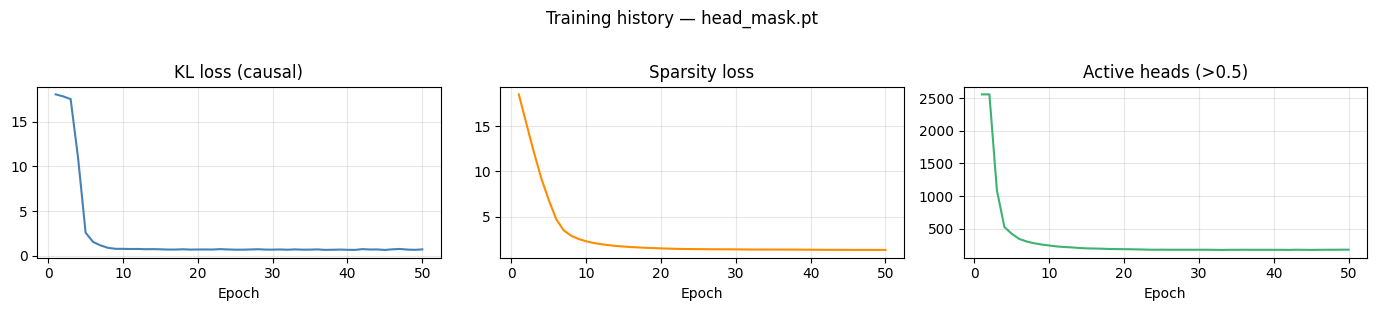

In [5]:
# Training curves from the checkpoint
from matplotlib import pyplot as plt
import numpy as np

plt.rcdefaults()

h = ckpt["history"]
xs = np.arange(1, len(h["loss_total"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(xs, h["loss_causal"],  color="steelblue");  axes[0].set_title("KL loss (causal)")
axes[1].plot(xs, h["loss_sparse"],  color="darkorange"); axes[1].set_title("Sparsity loss")
axes[2].plot(xs, h["n_active"],     color="mediumseagreen"); axes[2].set_title("Active heads (>0.5)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.suptitle(f"Training history — {os.path.basename(MASK_PATH)}", y=1.02)
plt.tight_layout()
plt.show()

2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: Matching Times New Roman:style=normal:variant=normal:weight=normal:stretch=normal:size=28.0.
2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/cmsy10.ttf', name='cmsy10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymReg.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizOneSymReg.ttf', name='STIXSizeOneSym

2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/usr/share/fonts/opentype/cabin/Cabin-Bold.otf', name='Cabin', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335
2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSerifGujarati-Bold.ttf', name='Noto Serif Gujarati', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335
2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSansInscriptionalParthian-Regular.ttf', name='Noto Sans Inscriptional Parthian', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-16 13:26:38 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/usr/share/fonts/truetype/msttcorefonts/Verdana.ttf', name='Verdana', style='normal', variant='normal', weight=400, s

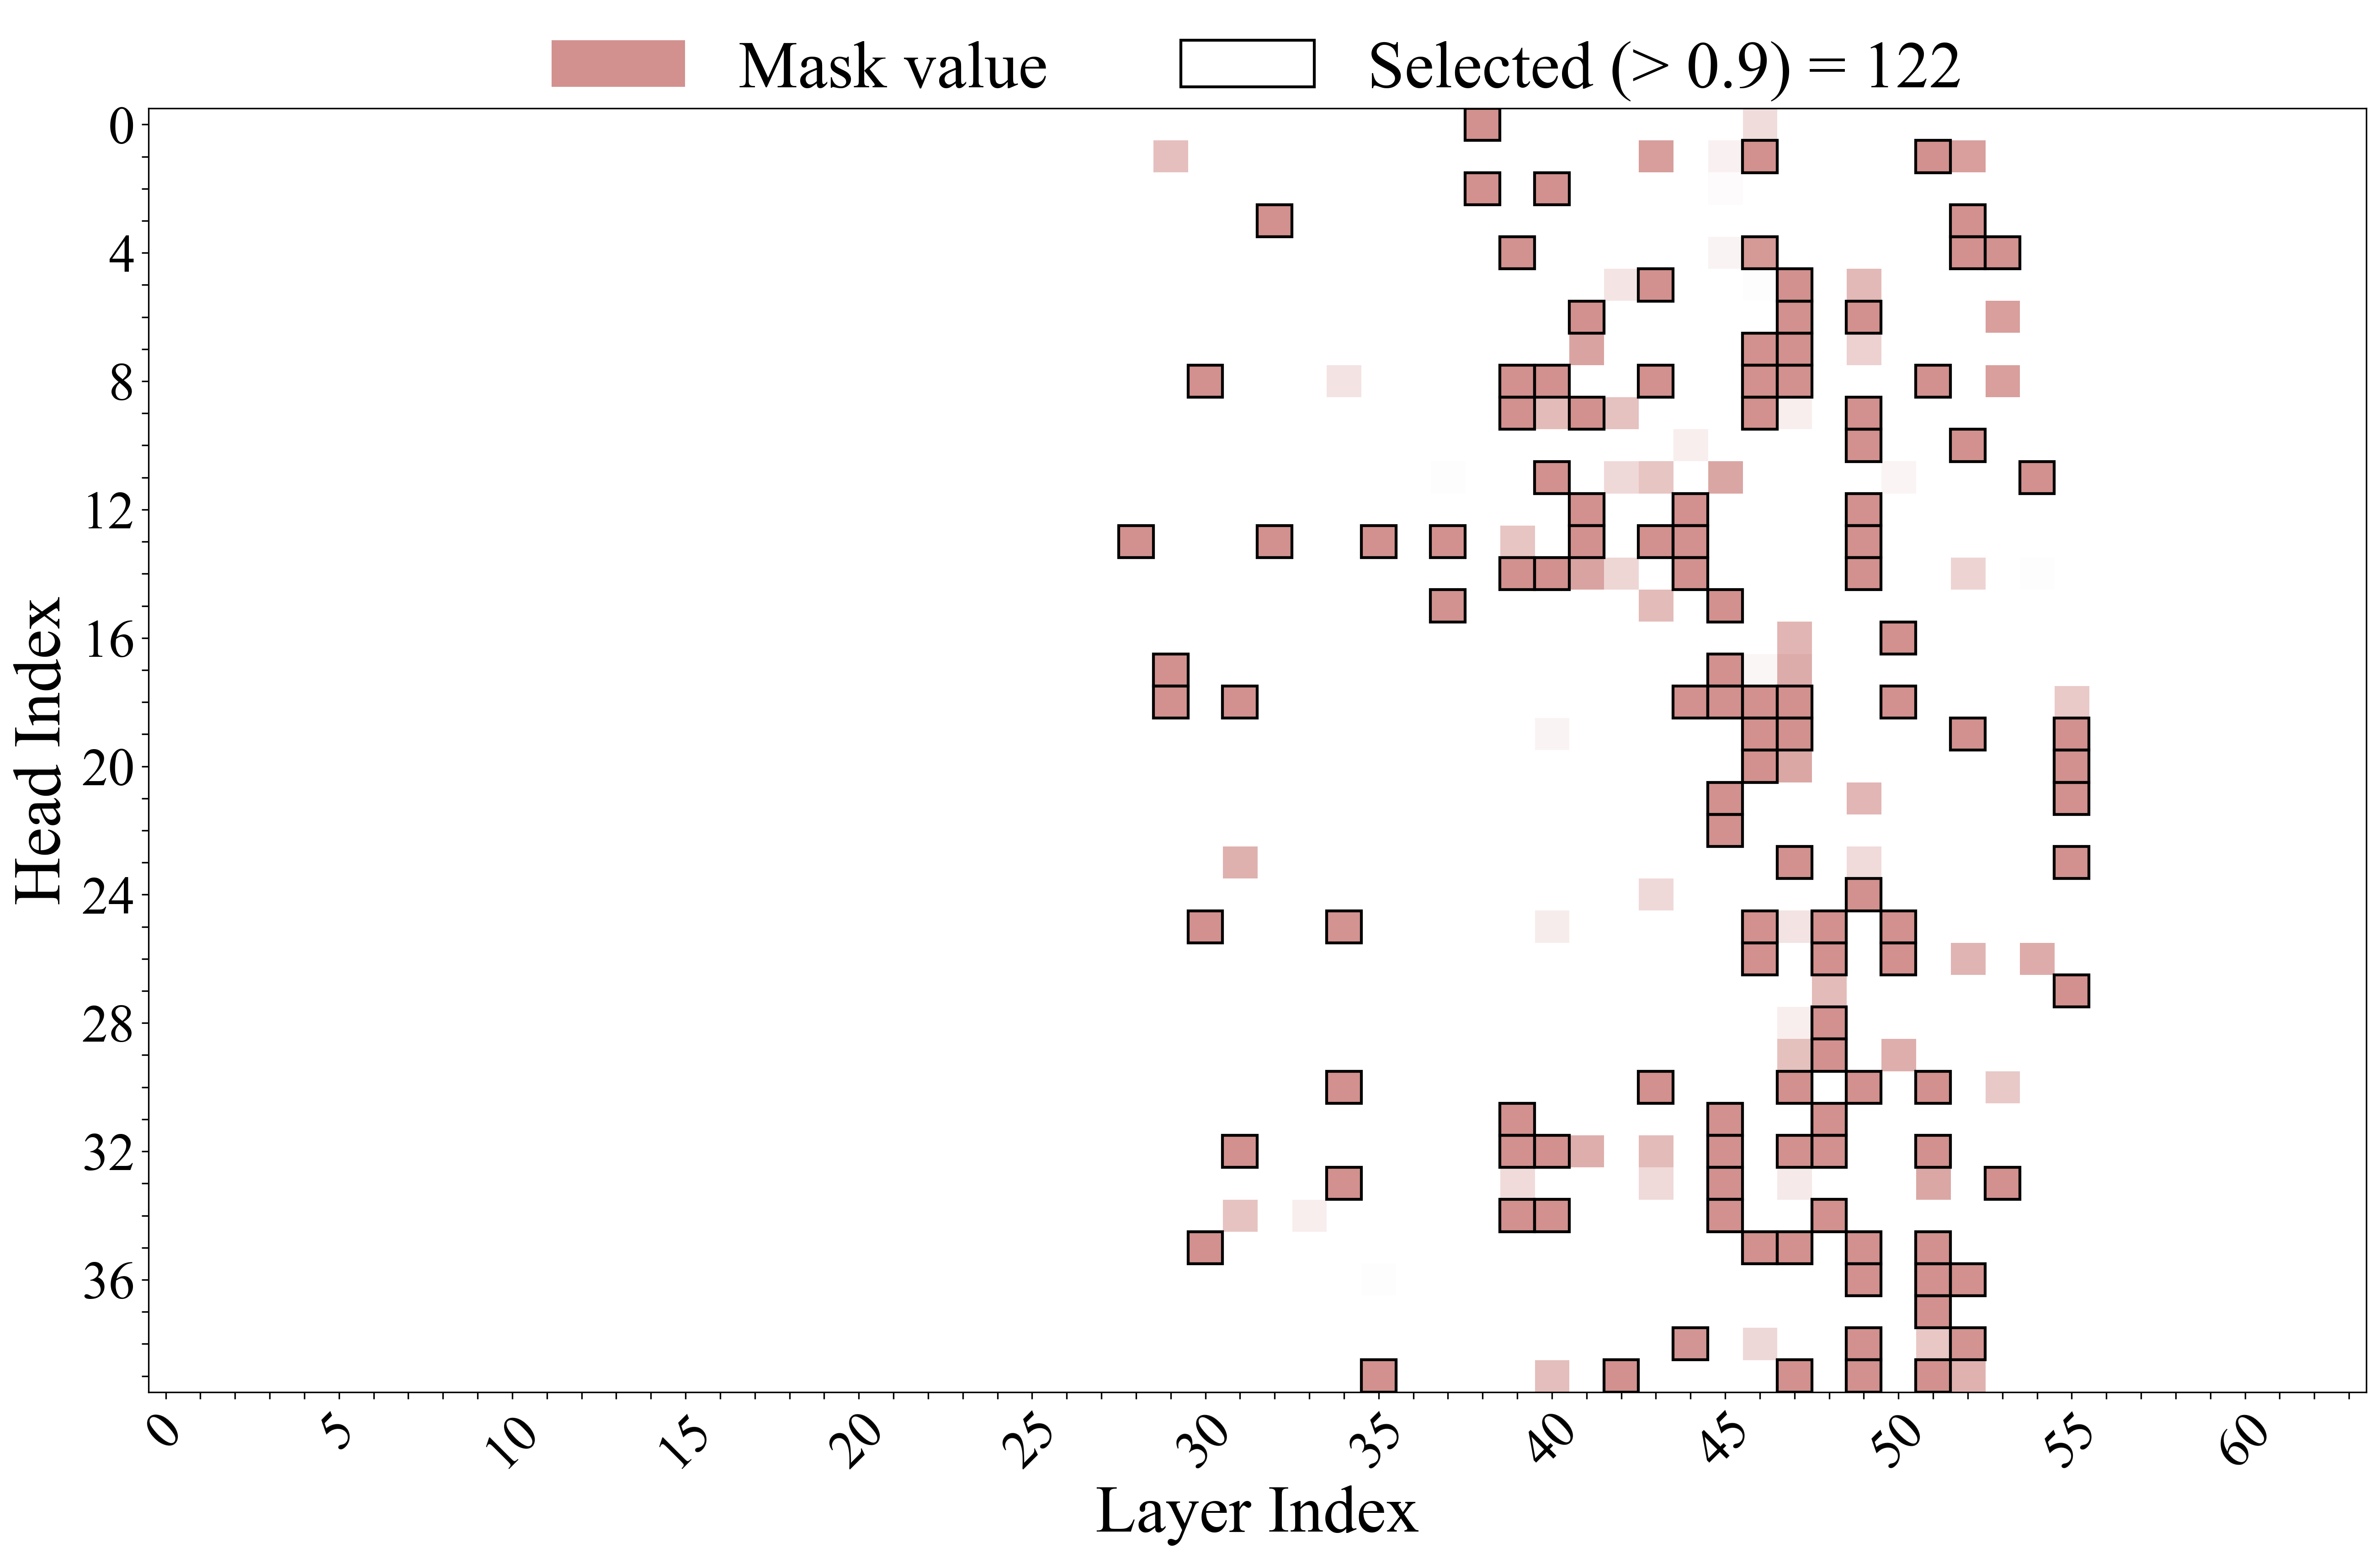

In [6]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in selected_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {threshold}) = {len(selected_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


In [7]:
import torch
from rich.console import Console
from rich.table import Table

from src.goals.head_loc_attn import (
    HeadMask,
    forward_with_src_replacement,
    get_o_proj_inputs_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.goals.goalscope import greedy_continue, patched_generate, patched_generate_batch
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ─────────────────
_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in selected_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

METRIC = "logit"  # "logit" or "prob"
MAX_NEW_TOKENS = 64
PATCH_ALL_TOKENS = True  # True → patch every generated token

_STOP_IDS = {mt.tokenizer.eos_token_id}


Binary mask: 122 active heads / 2560 total heads (4.77%)


In [8]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.data import IncompleteCodeDataset
import copy
from src.tokens import prepare_input

single_pred_dataset = IncompleteCodeDataset.load_dataset()
for sample in single_pred_dataset:
    print(sample.function_name)

SOURCE_PRED = "is_anagram"

source_sample = copy.deepcopy([
    d for d in single_pred_dataset if d.function_name == SOURCE_PRED
][0])

dest_sample = copy.deepcopy(source_sample)
dest_sample.instruction = "Complete the following python function.\n\n"
dest_sample.code = '''def func(args: any) -> any:\n    """'''
dest_sample.function_name = "func"

if supports_chat_template(mt):
    source_prompt = apply_chat_template(
        mt,
        user_query=source_sample.instruction.strip(),
        incomplete_code=source_sample.code,
    )
    dest_prompt = apply_chat_template(
        mt,
        user_query=dest_sample.instruction.strip(),
        incomplete_code=dest_sample.code,
    )
else:
    source_prompt = source_sample.code
    dest_prompt = dest_sample.code

# rich_print(f"Source prompt:\n[white]'''{source_prompt}'''[/white]")
# rich_print(f"Destination prompt:\n[white]'''{dest_prompt}'''[/white]")

dest_prompt = dest_prompt_aug

2026-04-16 13:27:28 src.goals.data INFO     Loaded 17 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json


is_odd
is_even
is_non_negative
is_negative
is_zero
is_palindrome
is_empty
is_uppercase
is_digit_string
is_vowel
is_power_of_two
is_sorted
has_duplicates
all_same
is_anagram
is_perfect_square
has_unique_elements


NameError: name 'dest_prompt_aug' is not defined

In [45]:
from src.goals.data import IncompleteCodeSample
import json

# test_sample = IncompleteCodeSample(
#     instruction="Write a python function that takes 3 integers base, power, modulo as input and returns (base ** power) % modulo. Make sure that your function is efficient and can handle large values of power without timing out.",
#     code='def mod_exp(base, power, modulo):\n    """',
#     unit_tests=[],
#     function_name="mod_exp",
#     prefills=[],
#     augmentation=None,
# )

# test_sample = IncompleteCodeSample(
#     instruction="Implement BFS graph traversal in Python.",
#     code='def bfs(graph, start):\n    """',
#     unit_tests=[],
#     function_name="bfs",
#     prefills=[],
#     augmentation=None,
# )

# test_sample = IncompleteCodeSample(
#     instruction="Implement a string to integer conversion in Python. Write your code without any comments or explanations, just the implementation.",
#     code='def atoi(s):\n    """',
#     unit_tests=[],
#     function_name="atoi",
#     prefills=[],
#     augmentation=None,
# )

# test_sample = IncompleteCodeSample(
#     instruction="Implement a stable marriage algorithm in Python. Write your code without any comments or explanations, just the implementation.",
#     code='def stable_marriage(',
#     unit_tests=[],
#     function_name="stable_marriage",
#     prefills=[],
#     augmentation=None,
# )
# test_sample.without_comments = True

test_sample = IncompleteCodeSample(
    instruction="Implement a stable marriage algorithm in C++. Write your code without any comments or explanations, just the implementation.",
    code='map<int, int> stable_marriage(',
    unit_tests=[],
    function_name="stable_marriage",
    prefills=[],
    augmentation=None,
)
test_sample.without_comments = True

# with open(os.path.join(env_utils.DEFAULT_DATA_DIR, "well-known-tasks", "merge_sort.json"), "r") as f:
#     test_sample_raw = json.load(f)

# test_sample = IncompleteCodeSample.from_dict(test_sample_raw)
# test_sample.without_comments = True

if supports_chat_template(mt):
    test_prompt = apply_chat_template(
        mt,
        user_query=test_sample.full_instruction.strip(),
        incomplete_code=test_sample.code,
    )
else:
    test_prompt = test_sample.code

rich_print(f"Test prompt:\n[white]'''{test_prompt}'''[/white]")

test_gen = greedy_continue(
    mt, **prepare_input(prompts=test_prompt, tokenizer=mt), max_new_tokens=512
)

rich_print(f"Greedy generation:\n[bright_yellow]'''{test_gen}'''[/bright_yellow]")

Test prompt:
'''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement a stable marriage algorithm in C++. Write your code without any comments or explanations, just the 
implementation. Write your code without any comments or explanations, just the implementation.<|im_end|>
<|im_start|>assistant
<code>
map<int, int> stable_marriage('''

Greedy generation:
'''2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count; i < n; ++i) {
        int woman = preference;
        if (stable_marriage == -1) {
            stable_marriage = free_man;
            engaged = true;
            break;
        } else {
            int current_man = stable_marriage;
            int rank_current_man = -1, rank_free_man = -1;
            for (int j = 0; j < n; ++j) {
                if (preference == current_man) rank_current_man = j;
                if (preference == free_man) rank_free_man = j;
            }
            if (rank_free_man < rank_current_man) {
                stable_marriage = free_man;
                engaged = true;
                engaged = false;
                break;
            }
        }
        proposal_count++;
    }
}
</code>'''

In [46]:
print(test_gen)

2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged[i]) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count[free_man]; i < n; ++i) {
        int woman = preference[free_man][i];
        if (stable_marriage[woman] == -1) {
            stable_marriage[woman] = free_man;
            engaged[free_man] = true;
            break;
        } else {
            int current_man = stable_marriage[woman];
            int rank_current_man = -1, rank_free_man = -1;
            for (int j = 0; j < n; ++j) {
                if (preference[woman][j] == current_man) rank_current_man = j;
                if (preference[woman][j] == free_man) rank_free_man = j;
            }
            if (rank_free_man < rank_current_man) {
                stable_marriage[woman]

In [47]:
# from src.goals.predicate_data import MultiPredicateDataset, TargetPredicate

# multi_dataset = MultiPredicateDataset.load_dataset()

# print(f"MultiPredicateDataset: {len(multi_dataset)} predicates")
# print(f"IncompleteCodeDataset: {len(single_pred_dataset)} samples")
# print(f"Available predicates: {[tp.name for tp in multi_dataset.groups]}")

# # ── Pick target predicate + sample ───────────────────────────────────────────
# PRED_NAME = "is_power_of_two"  # Change to pick a different predicate
# SAMPLE_IDX = 1

# target_predicate: TargetPredicate = next(tp for tp in multi_dataset.groups if tp.name == PRED_NAME)
# test_sample = target_predicate.samples[SAMPLE_IDX]

# print(f"Target predicate: {target_predicate.name!r}")
# print(f"  P+: {target_predicate.p_plus.description}")
# print(f"  P+ anchor tokens: {target_predicate.p_plus.anchor_patterns}")
# if test_sample.p_minus:
#     print(f"  P- (sample {SAMPLE_IDX}): {test_sample.p_minus.description}")
#     print(f"  P- anchor tokens: {test_sample.p_minus.anchor_patterns}")
# print(f"\nCode stub:\n{test_sample.code}")

# if supports_chat_template(mt):
#     test_prompt = apply_chat_template(
#         mt,
#         user_query=test_sample.instruction.strip(),
#         incomplete_code=test_sample.code,
#     )
# else:
#     test_prompt = test_sample.code

# test_gen = greedy_continue(
#     mt, **prepare_input(prompts=test_prompt, tokenizer=mt), max_new_tokens=256
# )

# rich_print(f"Test prompt:\n[white]'''{test_prompt}'''[/white]")
# rich_print(f"Greedy generation:\n[bright_yellow]'''{test_gen}'''[/bright_yellow]")

In [48]:
test_aug_sample = copy.deepcopy(test_sample)
pattern = "</code>"
prefill = test_gen.split(pattern)[0] + pattern
# rich_print(prefill)

test_aug_sample.code += prefill

test_aug_prompt = apply_chat_template(
    mt,
    user_query=test_aug_sample.instruction.strip(),
    incomplete_code=test_aug_sample.code,
)
rich_print(f"Augmented prompt:\n[white]'''{test_aug_prompt}'''[/white]")
source_prompt = test_aug_prompt

Augmented prompt:
'''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement a stable marriage algorithm in C++. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
map<int, int> stable_marriage(2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count; i < n; ++i) {
        int woman = preference;
        if (stable_marriage == -1) {
            stable_marriage = free_man;
            engaged = true;
            break;
        } else {
            int current_man = stable_marriage;
            int rank_current_man = -1, rank_free_man = -1;
            for (int j = 0; j < n; ++j) {
                if (preference == current_man) rank_current_man = j;
                if (preference == free_man) rank_free_man = j;
            }
            if (rank_free_man < rank_current_man) {
                stable_marriage = free_man;
                engaged = true;
                engaged = false;
                break;
            }
        }
        proposal_count++;
    }
}
</code>'''

In [49]:
src_tokenized = prepare_input(tokenizer=mt, prompts=source_prompt, return_offsets_mapping=True)
src_offsets = src_tokenized.pop("offset_mapping")[0]
dest_tokenized = prepare_input(tokenizer=mt, prompts=dest_prompt)

src_gen = greedy_continue(
    mt, src_tokenized["input_ids"], src_tokenized["attention_mask"], MAX_NEW_TOKENS
)
dest_gen = greedy_continue(
    mt, dest_tokenized["input_ids"], dest_tokenized["attention_mask"], MAX_NEW_TOKENS
)

rich_print(f"Source prompt:\n[white]{source_prompt}[/white][yellow]{src_gen}[/yellow]")
rich_print(
    f"Destination prompt:\n[white]{dest_prompt}[/white][yellow]{dest_gen}[/yellow]"
)

Source prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement a stable marriage algorithm in C++. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
map<int, int> stable_marriage(2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count; i < n; ++i) {
        int woman = preference;
        if (stable_marriage == -1) {
            stable_marriage = free_man;
            engaged = true;
            break;
        } else {
            int current_man = stable_marriage;
            int rank_current_man = -1, rank_free_man = -1;
            for (int j = 0; j < n; ++j) {
                if (preference == current_man) rank_current_man = j;
                if (preference == free_man) rank_free_man = j;
            }
            if (rank_free_man < rank_current_man) {
                stable_marriage = free_man;
                engaged = true;
                engaged = false;
                break;
            }
        }
        proposal_count++;
    }
}
</code>

Destination prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the following python function.<|im_end|>
<|im_start|>assistant
<code>
def func(args: any) -> any:
    """Complete the function based on the intended functionality."""
    # Example: If the function is supposed to return the square of a number
    if isinstance(args, (int, float)):
        return args ** 2
    else:
        raise ValueError("Input must be a number")

# Example usage:
# result = func

In [50]:
print(source_prompt)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement a stable marriage algorithm in C++. Write your code without any comments or explanations, just the implementation.<|im_end|>
<|im_start|>assistant
<code>
map<int, int> stable_marriage(2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged[i]) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count[free_man]; i < n; ++i) {
        int woman = preference[free_man][i];
        if (stable_marriage[woman] == -1) {
            stable_marriage[woman] = free_man;
            engaged[free_man] = true;
            break;
     

In [51]:
from scripts.run_goalscope import _find_code_segment

code_start, code_end = _find_code_segment(
    source_prompt=source_prompt,
    src_ids=src_tokenized["input_ids"][0].tolist(),
    mt=mt,
    src_offsets=src_offsets,    
)
print(code_start, code_end)
code_segment = "".join([mt.tokenizer.decode(t) for t in src_tokenized["input_ids"][0][code_start:code_end]])
rich_print(f"Code segment:\n[white]'''{code_segment}'''[/white]")

69 399


Code segment:
'''
<code>
map<int, int> stable_marriage(2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count; i < n; ++i) {
        int woman = preference;
        if (stable_marriage == -1) {
            stable_marriage = free_man;
            engaged = true;
            break;
        } else {
            int current_man = stable_marriage;
            int rank_current_man = -1, rank_free_man = -1;
            for (int j = 0; j < n; ++j) {
                if (preference == current_man) rank_current_man = j;
                if (preference == free_man) rank_free_man = j;
            }
            if (rank_free_man < rank_current_man) {
                stable_marriage = free_man;
                engaged = true;
                engaged = false;
                break;
            }
        }
        proposal_count++;
    }
}
</code>'''

In [52]:
from src.goals.head_loc_attn import get_o_proj_inputs_batch

src_o = get_o_proj_inputs_batch(mt, src_tokenized, LAYERS)
src_head_vals = torch.stack([src_o[ly][0] for ly in LAYERS])

patched_gen = patched_generate(
    mt = mt,
    dest_inputs=dest_tokenized,
    src_head_vals=src_head_vals,
    mask=binary_mask,
    layers=LAYERS,
    max_new_tokens=64,
    stop_ids=_STOP_IDS,
)

rich_print(f"Patched prompt:\n[white]{dest_prompt}[/white][salmon1]{patched_gen}[/salmon1]")

Patched prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the following python function.<|im_end|>
<|im_start|>assistant
<code>
def func(args: any) -> any:
    """A placeholder for a function that needs to be completed.
    
    Args:
        args: The input arguments for the function.
        
    Returns:
        The result of the function.
    """
    # Assuming the task is to process some data, here is a generic template
    # This is a placeholder and should be

## PatchScope Visualization

For each generated token in the source prompt, patch the selected head outputs at that token position into the docstring position of the destination prompt, and run greedy generation. Hover over a source token to see what the model verbalizes.

In [19]:
rich_print(f"[white]{source_prompt}[/white]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement a stable marriage algorithm in C++. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
map<int, int> stable_marriage(2 * n, -1);
vector<vector<int>> preference(n, vector<int>(n));
vector<int> proposal_count(n, 0);
vector<bool> engaged(n, false);

while (true) {
    int free_man = -1;
    for (int i = 0; i < n; ++i) {
        if (!engaged) {
            free_man = i;
            break;
        }
    }
    if (free_man == -1) break;

    for (int i = proposal_count; i < n; ++i) {
        int woman = preference;
        if (stable_marriage == -1) {
            stable_marriage = free_man;
            engaged = true;
            break;
        } else {
            int current_man = stable_marriage;
            int rank_current_man = -1, rank_free_man = -1;
            for (int j = 0; j < n; ++j) {
                if (preference == current_man) rank_current_man = j;
                if (preference == free_man) rank_free_man = j;
            }
            if (rank_free_man < rank_current_man) {
                stable_marriage = free_man;
                engaged = true;
                engaged = false;
                break;
            }
        }
        proposal_count++;
    }
}
</code>

In [20]:
# ── Collect per-token patched verbalization (batched) ─────────────────────
from tqdm.auto import tqdm
import math

src_tokenized = prepare_input(tokenizer=mt, prompts=source_prompt)
src_ids = src_tokenized["input_ids"][0].tolist()
src_text_tokens = [mt.tokenizer.decode([t]) for t in src_ids]
n_src = len(src_ids)

# Extract o_proj inputs for the interested segment in one forward pass
interested_segment = (code_start, len(src_ids))
seg_positions = list(range(*interested_segment))

src_o_seg = get_o_proj_inputs_batch(
    mt, src_tokenized, LAYERS, token_positions=seg_positions
)  # {layer: (1, n_seg, n_embd)}

dest_tokenized_fresh = prepare_input(tokenizer=mt, prompts=dest_prompt)

BATCH_SIZE = 16  # tune based on VRAM; each item = one full dest-prompt generation

patchscope_results: list[dict] = []
print(f"Source tokens: {n_src}   Segment: {interested_segment}  ({len(seg_positions)} positions)")
print(f"Batch size: {BATCH_SIZE}   Batches: {math.ceil(len(seg_positions) / BATCH_SIZE)}")

for chunk_start in tqdm(range(0, len(seg_positions), BATCH_SIZE)):
    chunk = seg_positions[chunk_start : chunk_start + BATCH_SIZE]

    # Stack source head vals for this chunk: (B, n_layers, n_embd)
    src_head_vals_batch = 1.5 * torch.stack(
        [torch.stack([src_o_seg[ly][0, chunk_start + i] for ly in LAYERS])
         for i in range(len(chunk))]
    )

    patched_gens = patched_generate_batch(
        mt=mt,
        dest_inputs={k: v.clone() for k, v in dest_tokenized_fresh.items()},
        src_head_vals_batch=src_head_vals_batch,
        mask=binary_mask,
        layers=LAYERS,
        max_new_tokens=16,
        stop_ids=_STOP_IDS,
    )

    for i, pos in enumerate(chunk):
        patchscope_results.append({
            "pos": pos,
            "token": src_text_tokens[pos],
            "patched_gen": patched_gens[i],
        })

print(f"Done. {len(patchscope_results)} positions collected.")


Source tokens: 399   Segment: (69, 399)  (330 positions)
Batch size: 16   Batches: 21


  0%|          | 0/21 [00:00<?, ?it/s]

Done. 330 positions collected.


In [21]:
src_o_seg[5].shape

torch.Size([1, 330, 5120])

In [22]:
from src.goals.goalscope import render_patchscope_html, show_patchscope


# ── Display (and optionally save) ─────────────────────────────────────────
html_save_dir = "results/patchscope"
os.makedirs(html_save_dir, exist_ok=True)
show_patchscope(
    patchscope_results,
    title=f"PatchScope: {test_aug_sample.function_name} → {dest_sample.function_name}",
    save_path=f"{html_save_dir}/{test_aug_sample.function_name}_wo_comments.html",   # set to None to skip saving
)


Saved -> results/patchscope/stable_marriage_wo_comments.html


## Head-Output Steering

Alternative patchscope variant: instead of replacing o_proj inputs, **sum the
residual-stream contributions** of the selected heads at each source token, then
**add** that vector to the destination's residual stream during generation
(at every layer in `STEER_LAYER_RANGE`, at every decode step).

Uses `generate_with_patch` with `strategy='add'` and `on_pass='all'`.
Output format is identical to the o_proj-replacement patchscope, so the same
`show_patchscope` visualization works directly.

In [53]:
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.functional import PatchSpec, generate_with_patch

# Layer range over which to inject the steering vector (inclusive)
STEER_LAYER_RANGE = (35, 46)   # e.g. (6, 40) — same as training range
STEER_BATCH_SIZE  = 16                          # source positions per generate call
STEER_MAX_TOKENS  = 64
ALPHA             = 0.2                         # steering strength multiplier

In [54]:
from scripts.run_goalscope import _build_dest_prompt

print(dest_prompt)

dest_prompt_aug = _build_dest_prompt(mt)
print(dest_prompt_aug)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the following python function.<|im_end|>
<|im_start|>assistant
<code>
def func(args: any) -> any:
    """
<|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
What are you doing at this line of the code. Keep your answer as brief as possible.<|im_end|>
<|im_start|>assistant



In [56]:
interested_segment

"<|im_start|>assistant\nLet's break down the problem step by step.\n\n1. In April, Natalia sold clips to 48 friends.\n2. In May, she sold half as many clips as she did in April. So, we need to calculate half of 48:\n   \\[\n   \\frac{48}{2} = 24\n   \\]\n3. To find out how many clips Natalia sold altogether in April and May, we add the number of clips sold in April to the number of clips sold in May:\n   \\[\n   48 + 24 = 72\n   \\]\n\nSo, the total number of clips Natalia sold in April and May is 72.\n\n<ans>72</ans>"

In [57]:
# ── Collect per-position steering vectors (single forward pass) ───────────
src_tokenized_steer = prepare_input(tokenizer=mt, prompts=source_prompt)
src_ids_steer = src_tokenized_steer["input_ids"][0].tolist()
src_text_tokens_steer = [mt.tokenizer.decode([t]) for t in src_ids_steer]
n_src_steer = len(src_ids_steer)

# Use the same segment as the o_proj-replacement patchscope
interested_segment = (code_start, code_end)
seg_positions_steer = list(range(*interested_segment))  # reuse from earlier cells

steering_vecs = collect_head_steering_vecs(
    mt=mt,
    src_tokenized=src_tokenized_steer,
    selected_heads=selected_heads,      # list of (layer, head) from trained mask
    token_positions=seg_positions_steer,
)  # (n_positions, n_embd) float32 CPU

print(f"Steering vectors: {steering_vecs.shape}")
print(f"Norm range: [{steering_vecs.norm(dim=-1).min():.2f}, "
      f"{steering_vecs.norm(dim=-1).max():.2f}]")
len(range(*interested_segment)), len(selected_heads)

Steering vectors: torch.Size([330, 5120])
Norm range: [110.64, 288.75]


(330, 122)

In [58]:
from src.functional import get_hs

steering_hs = get_hs(
    mt=mt,
    input=src_tokenized_steer,
    locations=[
        (mt.layer_name_format.format(ly), token_idx)
        for ly in range(*STEER_LAYER_RANGE)
        for token_idx in seg_positions_steer
    ],
)

hs_by_layer = {ly: [] for ly in range(*STEER_LAYER_RANGE)}
for ly in range(*STEER_LAYER_RANGE):
    for token_idx in seg_positions_steer:
        hs_by_layer[ly].append(steering_hs[(mt.layer_name_format.format(ly), token_idx)])
    hs_by_layer[ly] = torch.stack(hs_by_layer[ly], dim=0)  # (n_positions, d_model)

hs_by_layer[35].shape

torch.Size([330, 5120])

In [59]:
print(dest_prompt_aug)

<|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
What are you doing at this line of the code. Keep your answer as brief as possible.<|im_end|>
<|im_start|>assistant



In [60]:
# ── Batched steering generation via generate_with_patch ───────────────────
import math
from tqdm.auto import tqdm
from src.tokens import TokenizerOutput

dest_tokenized_steer = prepare_input(tokenizer=mt, prompts=dest_prompt_aug)
dest_ids_steer = dest_tokenized_steer["input_ids"]  # (1, seq)
dest_mask_steer = dest_tokenized_steer["attention_mask"]

layer_start, layer_to = STEER_LAYER_RANGE
steer_layers = list(range(layer_start, layer_to))

patchscope_steer_results: list[dict] = []

n_seg = len(seg_positions_steer)
print(
    f"Positions: {n_seg}  |  Batch size: {STEER_BATCH_SIZE}  "
    f"|  Batches: {math.ceil(n_seg / STEER_BATCH_SIZE)}"
)

for chunk_start in tqdm(range(0, n_seg, STEER_BATCH_SIZE)):
    chunk_end = min(chunk_start + STEER_BATCH_SIZE, n_seg)
    B = chunk_end - chunk_start

    # Steering vectors for this chunk: (B, n_embd)
    sv_batch = ALPHA*steering_vecs[chunk_start:chunk_end]  # (B, n_embd)

    # Tile dest prompt to batch size B
    tiled_inputs = TokenizerOutput(
        data=dict(
            input_ids=dest_ids_steer.expand(B, -1).clone(),
            attention_mask=dest_mask_steer.expand(B, -1).clone(),
        )
    )

    # One PatchSpec per layer: add sv_batch at position -1 at every decode step
    patches = [
        PatchSpec(
            location=(mt.layer_name_format.format(li), -1),
            patch=sv_batch,
            strategy="add",
            on_pass="all",
        )
        for li in steer_layers
    ]

    # # Full layer patching -- not head-specific
    # patches = []
    # for li in steer_layers:
    #     patch_chunk = 0.1 * hs_by_layer[li][chunk_start: chunk_end]  # (B, n_embd)
    #     patches.append(
    #         PatchSpec(
    #             location=(mt.layer_name_format.format(li), -1),
    #             patch=patch_chunk,
    #             strategy="add",
    #             on_pass="all",
    #         )
    #     )

    gens = generate_with_patch(
        mt,
        tiled_inputs,
        max_new_tokens=STEER_MAX_TOKENS,
        patches=patches,
        do_sample=False,
        patch_interface="baukit",
        remove_prefix=True,
        skip_special_tokens=True,
    )  # list[str] of length B

    for i in range(B):
        src_pos = seg_positions_steer[chunk_start + i]
        patchscope_steer_results.append(
            {
                "pos": src_pos,
                "token": src_text_tokens_steer[src_pos],
                "patched_gen": gens[i],
            }
        )

print(f"Done. {len(patchscope_steer_results)} positions collected.")


Positions: 330  |  Batch size: 16  |  Batches: 21


  0%|          | 0/21 [00:00<?, ?it/s]

Done. 330 positions collected.


In [61]:
# ── Visualize (same show_patchscope util) ─────────────────────────────────

show_patchscope(
    patchscope_steer_results,
    title=f"Head-Output Steering: {test_aug_sample.function_name} → {dest_sample.function_name}",
    save_path=f"results/patchscope/steering_{test_aug_sample.function_name}_cpp_head_output.html",
)

Saved -> results/patchscope/steering_stable_marriage_cpp_head_output.html


In [80]:
from src.functional import generate_with_patch

# messages = [
#     {
#         "role": "system",
#         "content": "You are a helpful assistant",
#     },
#     {
#         "role": "user",
#         "content": "Give me a short rhyme",
#     },
#     {
#         "role": "assistant",
#         "content": "He saw a carrot and he had to grab it.\n",
#     },
# ]

messages = [
    {
        "role": "system",
        "content": "You are a helpful assistant",
    },
    {
        "role": "user",
        "content": """Solve this simple math problem:

Joy can read 8 pages of a book in 20 minutes. How many hours will it take her to read 120 pages?

Think step by step. Provide your answer in <ans> </ans> tags.
""",
    },
    {
        "role": "assistant",
        "content": "",
    },
]

rhyme_prompt = mt.tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=False,  # Don't add a new assistant header
    continue_final_message=True,  # Don't close the assistant turn with <|eot_id|>
    tokenize=False,
    chat_template_kwargs={"enable_thinking": False},  # only Qwen3 and Qwen3.5
)

rhyme_prompt_tokenized = prepare_input(rhyme_prompt, tokenizer=mt, return_offsets_mapping=True)
offsets = rhyme_prompt_tokenized.pop("offset_mapping")[0]

rhyme_gen = generate_with_patch(
    mt = mt,
    inputs = rhyme_prompt_tokenized,
    max_new_tokens=256,
    remove_prefix=True,
    do_sample=False
)[0]

rich_print(f"[white]{rhyme_prompt}[/white][bright_yellow]{rhyme_gen}[/bright_yellow]")

<|im_start|>system
You are a helpful assistant<|im_end|>
<|im_start|>user
Solve this simple math problem:

Joy can read 8 pages of a book in 20 minutes. How many hours will it take her to read 120 pages?

Think step by step. Provide your answer in <ans> </ans> tags.
<|im_end|>
<|im_start|>assistant
To solve the problem, we need to determine how long it takes Joy to read one page and then use that information to 
find out how long it will take her to read 120 pages.

Step 1: Calculate the time it takes Joy to read one page.
Joy reads 8 pages in 20 minutes. Therefore, the time to read one page is:
[ \text{Time per page} = \frac{20 \text{ minutes}}{8 \text{ pages}} = 2.5 \text{ minutes per page} \]

Step 2: Calculate the total time to read 120 pages.
If it takes 2.5 minutes to read one page, then for 120 pages, the total time required is:
[ \text{Total time} = 2.5 \text{ minutes/page} \times 120 \text{ pages} = 300 \text{ minutes} \]

Step 3: Convert the total time from minutes to hours.
Since there are 60 minutes in an hour, we convert 300 minutes to hours by dividing by 60:
[ \text{Total time in hours} = \frac{300

In [83]:
rhyme_dest_messages = [
    {
        "role": "system",
        "content": "You are a helpful assistant.",
    },
    {
        "role": "user",
        "content": "You are solving a simple math problem. At this specific token position, tell me what you are planning to do next.",
    },
    {
        "role": "assistant",
        "content": "",
    },
]

rhyme_dest_prompt = _build_dest_prompt(mt=mt, messages=rhyme_dest_messages)
print(rhyme_dest_prompt)

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
You are solving a simple math problem. At this specific token position, tell me what you are planning to do next.<|im_end|>
<|im_start|>assistant



In [84]:
# ── Batched steering generation via generate_with_patch ───────────────────
import math
from tqdm.auto import tqdm
from src.tokens import TokenizerOutput, find_token_range

dest_tokenized_steer = prepare_input(tokenizer=mt, prompts=rhyme_dest_prompt)
dest_ids_steer = dest_tokenized_steer["input_ids"]  # (1, seq)
dest_mask_steer = dest_tokenized_steer["attention_mask"]

layer_start, layer_to = STEER_LAYER_RANGE
steer_layers = list(range(layer_start, layer_to))

patchscope_steer_results: list[dict] = []

rhyme_full_text = rhyme_prompt + rhyme_gen
rhyme_tokenized = prepare_input(rhyme_full_text, tokenizer=mt, return_offsets_mapping=True)
offsets = rhyme_tokenized.pop("offset_mapping")[0]

assistant_ans_start, _ = find_token_range(
    string=rhyme_full_text,
    substring=">assistant",
    tokenizer=mt,
    offset_mapping=offsets,
    occurrence=0,  # second occurrence of <ans> (the first one is in the system prompt)
)

if "</ans>" in rhyme_gen:
    _, assistant_ans_end = find_token_range(
        string=rhyme_full_text,
        substring="</ans>",
        tokenizer=mt,
        offset_mapping=offsets,
        occurrence=1,
    )
else:
    assistant_ans_end = len(rhyme_tokenized["input_ids"][0])

seg_positions_steer = list(range(assistant_ans_start, assistant_ans_end))

src_tokens = [mt.tokenizer.decode([t]) for t in rhyme_tokenized["input_ids"][0]]
interested_segment = "".join(src_tokens[assistant_ans_start:assistant_ans_end])
rich_print(f"Steering segment ({assistant_ans_start}-{assistant_ans_end}):\n[white]'''{interested_segment}'''[/white]")

n_seg = len(seg_positions_steer)
print(
    f"Positions: {n_seg}  |  Batch size: {STEER_BATCH_SIZE}  "
    f"|  Batches: {math.ceil(n_seg / STEER_BATCH_SIZE)}"
)

steering_vecs = collect_head_steering_vecs(
    mt=mt,
    src_tokenized=rhyme_tokenized,
    selected_heads=selected_heads,      # list of (layer, head) from trained mask
    token_positions=seg_positions_steer,
)  # (n_positions, n_embd) float32 CPU

for chunk_start in tqdm(range(0, n_seg, STEER_BATCH_SIZE)):
    chunk_end = min(chunk_start + STEER_BATCH_SIZE, n_seg)
    B = chunk_end - chunk_start

    # Steering vectors for this chunk: (B, n_embd)
    sv_batch = ALPHA*steering_vecs[chunk_start:chunk_end]  # (B, n_embd)

    # Tile dest prompt to batch size B
    tiled_inputs = TokenizerOutput(
        data=dict(
            input_ids=dest_ids_steer.expand(B, -1).clone(),
            attention_mask=dest_mask_steer.expand(B, -1).clone(),
        )
    )

    # One PatchSpec per layer: add sv_batch at position -1 at every decode step
    patches = [
        PatchSpec(
            location=(mt.layer_name_format.format(li), -1),
            patch=sv_batch,
            strategy="add",
            on_pass="all",
        )
        for li in steer_layers
    ]

    # # Full layer patching -- not head-specific
    # patches = []
    # for li in steer_layers:
    #     patch_chunk = 0.1 * hs_by_layer[li][chunk_start: chunk_end]  # (B, n_embd)
    #     patches.append(
    #         PatchSpec(
    #             location=(mt.layer_name_format.format(li), -1),
    #             patch=patch_chunk,
    #             strategy="add",
    #             on_pass="all",
    #         )
    #     )

    gens = generate_with_patch(
        mt,
        tiled_inputs,
        max_new_tokens=STEER_MAX_TOKENS,
        patches=patches,
        do_sample=False,
        patch_interface="baukit",
        remove_prefix=True,
        skip_special_tokens=True,
    )  # list[str] of length B

    for i in range(B):
        src_pos = seg_positions_steer[chunk_start + i]
        patchscope_steer_results.append(
            {
                "pos": src_pos,
                "token": src_tokens[src_pos],
                "patched_gen": gens[i],
            }
        )

print(f"Done. {len(patchscope_steer_results)} positions collected.")


Steering segment (69-328):
'''<|im_start|>assistant
To solve the problem, we need to determine how long it takes Joy to read one page and then use that information to 
find out how long it will take her to read 120 pages.

Step 1: Calculate the time it takes Joy to read one page.
Joy reads 8 pages in 20 minutes. Therefore, the time to read one page is:
[ \text{Time per page} = \frac{20 \text{ minutes}}{8 \text{ pages}} = 2.5 \text{ minutes per page} \]

Step 2: Calculate the total time to read 120 pages.
If it takes 2.5 minutes to read one page, then for 120 pages, the total time required is:
[ \text{Total time} = 2.5 \text{ minutes/page} \times 120 \text{ pages} = 300 \text{ minutes} \]

Step 3: Convert the total time from minutes to hours.
Since there are 60 minutes in an hour, we convert 300 minutes to hours by dividing by 60:
[ \text{Total time in hours} = \frac{300'''

Positions: 259  |  Batch size: 16  |  Batches: 17


  0%|          | 0/17 [00:00<?, ?it/s]

Done. 259 positions collected.


In [85]:
# ── Visualize (same show_patchscope util) ─────────────────────────────────
show_patchscope(
    patchscope_steer_results,
    title=f"Head-Output Steering: Rhyming test → {dest_sample.function_name}",
    # save_path=f"results/patchscope/steering_{test_aug_sample.function_name}_wo_comments.html",
)

In [86]:
from src.functional import generate_with_patch

messages = [
    {
        "role": "system",
        "content": "You are a helpful assistant",
    },
    {
        "role": "user",
        "content": "Give me a short rhyme",
    },
    {
        "role": "assistant",
        "content": "He saw a carrot and he had to grab it.\n",
    },
]

rhyme_prompt = mt.tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=False,  # Don't add a new assistant header
    continue_final_message=True,  # Don't close the assistant turn with <|eot_id|>
    tokenize=False,
    chat_template_kwargs={"enable_thinking": False},  # only Qwen3 and Qwen3.5
)

rhyme_prompt_tokenized = prepare_input(rhyme_prompt, tokenizer=mt, return_offsets_mapping=True)
offsets = rhyme_prompt_tokenized.pop("offset_mapping")[0]

rhyme_gen = generate_with_patch(
    mt = mt,
    inputs = rhyme_prompt_tokenized,
    max_new_tokens=256,
    remove_prefix=True,
    do_sample=False
)[0]

rich_print(f"[white]{rhyme_prompt}[/white][bright_yellow]{rhyme_gen}[/bright_yellow]")

<|im_start|>system
You are a helpful assistant<|im_end|>
<|im_start|>user
Give me a short rhyme<|im_end|>
<|im_start|>assistant
He saw a carrot and he had to grab it.
In the garden, it was quite a fab hit!

In [73]:
rhyme_dest_messages = [
    {
        "role": "system",
        "content": "You are a helpful assistant.",
    },
    {
        "role": "user",
        "content": "You are making a rhyme. At this specific token position, tell me what you are planning to do.",
    },
    {
        "role": "assistant",
        "content": "",
    },
]

rhyme_dest_prompt = _build_dest_prompt(mt=mt, messages=rhyme_dest_messages)
print(rhyme_dest_prompt)

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
You are making a rhyme. At this specific token position, tell me what you are planning to do.<|im_end|>
<|im_start|>assistant



In [74]:
# ── Batched steering generation via generate_with_patch ───────────────────
import math
from tqdm.auto import tqdm
from src.tokens import TokenizerOutput, find_token_range

dest_tokenized_steer = prepare_input(tokenizer=mt, prompts=rhyme_dest_prompt)
dest_ids_steer = dest_tokenized_steer["input_ids"]  # (1, seq)
dest_mask_steer = dest_tokenized_steer["attention_mask"]

layer_start, layer_to = STEER_LAYER_RANGE
steer_layers = list(range(layer_start, layer_to))

patchscope_steer_results: list[dict] = []

rhyme_full_text = rhyme_prompt + rhyme_gen
rhyme_tokenized = prepare_input(rhyme_full_text, tokenizer=mt, return_offsets_mapping=True)
offsets = rhyme_tokenized.pop("offset_mapping")[0]

assistant_ans_start, _ = find_token_range(
    string=rhyme_full_text,
    substring=">assistant",
    tokenizer=mt,
    offset_mapping=offsets,
    occurrence=0,  # second occurrence of <ans> (the first one is in the system prompt)
)

if "</ans>" in rhyme_gen:
    _, assistant_ans_end = find_token_range(
        string=rhyme_full_text,
        substring="</ans>",
        tokenizer=mt,
        offset_mapping=offsets,
        occurrence=1,
    )
else:
    assistant_ans_end = len(rhyme_tokenized["input_ids"][0])

seg_positions_steer = list(range(assistant_ans_start, assistant_ans_end))

src_tokens = [mt.tokenizer.decode([t]) for t in rhyme_tokenized["input_ids"][0]]
interested_segment = "".join(src_tokens[assistant_ans_start:assistant_ans_end])
rich_print(f"Steering segment ({assistant_ans_start}-{assistant_ans_end}):\n[white]'''{interested_segment}'''[/white]")

n_seg = len(seg_positions_steer)
print(
    f"Positions: {n_seg}  |  Batch size: {STEER_BATCH_SIZE}  "
    f"|  Batches: {math.ceil(n_seg / STEER_BATCH_SIZE)}"
)

steering_vecs = collect_head_steering_vecs(
    mt=mt,
    src_tokenized=rhyme_tokenized,
    selected_heads=selected_heads,      # list of (layer, head) from trained mask
    token_positions=seg_positions_steer,
)  # (n_positions, n_embd) float32 CPU

for chunk_start in tqdm(range(0, n_seg, STEER_BATCH_SIZE)):
    chunk_end = min(chunk_start + STEER_BATCH_SIZE, n_seg)
    B = chunk_end - chunk_start

    # Steering vectors for this chunk: (B, n_embd)
    sv_batch = ALPHA*steering_vecs[chunk_start:chunk_end]  # (B, n_embd)

    # Tile dest prompt to batch size B
    tiled_inputs = TokenizerOutput(
        data=dict(
            input_ids=dest_ids_steer.expand(B, -1).clone(),
            attention_mask=dest_mask_steer.expand(B, -1).clone(),
        )
    )

    # One PatchSpec per layer: add sv_batch at position -1 at every decode step
    patches = [
        PatchSpec(
            location=(mt.layer_name_format.format(li), -1),
            patch=sv_batch,
            strategy="add",
            on_pass="all",
        )
        for li in steer_layers
    ]

    # # Full layer patching -- not head-specific
    # patches = []
    # for li in steer_layers:
    #     patch_chunk = 0.1 * hs_by_layer[li][chunk_start: chunk_end]  # (B, n_embd)
    #     patches.append(
    #         PatchSpec(
    #             location=(mt.layer_name_format.format(li), -1),
    #             patch=patch_chunk,
    #             strategy="add",
    #             on_pass="all",
    #         )
    #     )

    gens = generate_with_patch(
        mt,
        tiled_inputs,
        max_new_tokens=STEER_MAX_TOKENS,
        patches=patches,
        do_sample=False,
        patch_interface="baukit",
        remove_prefix=True,
        skip_special_tokens=True,
    )  # list[str] of length B

    for i in range(B):
        src_pos = seg_positions_steer[chunk_start + i]
        patchscope_steer_results.append(
            {
                "pos": src_pos,
                "token": src_tokens[src_pos],
                "patched_gen": gens[i],
            }
        )

print(f"Done. {len(patchscope_steer_results)} positions collected.")


# ── Visualize (same show_patchscope util) ─────────────────────────────────
show_patchscope(
    patchscope_steer_results,
    title=f"Head-Output Steering: Rhyming test → {dest_sample.function_name}",
    # save_path=f"results/patchscope/steering_{test_aug_sample.function_name}_wo_comments.html",
)

Steering segment (20-45):
'''<|im_start|>assistant
He saw a carrot and he had to grab it.
In the garden, it was quite a fab hit!'''

Positions: 25  |  Batch size: 16  |  Batches: 2


  0%|          | 0/2 [00:00<?, ?it/s]

Done. 25 positions collected.
